# CP2/CP3 — Assistente de atendimento de e-commerce com SmolLM2-360M, RAG e LoRA

**Disciplina:** Generative AI for Engineering — Prof. Dr. Francisco Elânio
**Turma:** 4ESR-2026

| Integrante | RM |
|---|---|
| Rodrigo Paixão Silveira | 96869 |
| _(nome)_ | _(RM)_ |
| _(nome)_ | _(RM)_ |
| _(nome)_ | _(RM)_ |

## Problema escolhido

Uma loja virtual fictícia recebe chamados de clientes escritos em português (atraso na entrega, produto com defeito, troca, reembolso, cancelamento, pagamento recusado, cupom e fraude). O objetivo é treinar **localmente, em GPU,** uma LLM pequena para:

1. receber o chamado do cliente;
2. consultar a base de políticas da loja (**RAG**);
3. classificar **categoria** e **prioridade** e indicar a **equipe** responsável;
4. devolver um **JSON** com o procedimento e a **fonte** (documento) usada;
5. responder `sem_informacao` quando a base não cobre a pergunta, em vez de inventar.

| Componente | Escolha |
|---|---|
| LLM | [`HuggingFaceTB/SmolLM2-360M-Instruct`](https://huggingface.co/HuggingFaceTB/SmolLM2-360M-Instruct) |
| Embeddings (RAG) | [`sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2) |
| Fine-tuning | LoRA (PEFT) — só um adaptador pequeno é treinado |
| Frontend | Gradio |

> **Ideia central:** o fine-tuning ensina **como responder** (formato JSON, rótulos válidos, recusar quando não sabe); o RAG fornece **o conhecimento** usado na resposta.

### Melhorias em relação ao notebook da Aula 9

- **Limiar do RAG escolhido por experimento** (seção 6), em vez de fixo em 0,55.
- **Valores permitidos no system prompt**, para o modelo não inventar rótulos (como "moderada").
- **Treino com documento distrator**: parte dos exemplos traz 2 documentos no contexto (o certo e um errado), como acontece na busca real com `top_k=2`.
- **Exemplos negativos com documento irrelevante** no contexto, ensinando a responder `sem_informacao` mesmo quando a busca traz algo.
- **Validação separada por frase** (a mesma frase nunca aparece no treino e na validação).
- **Vários experimentos de hiperparâmetros** comparados automaticamente (seção 11).

## 1. Preparação do ambiente (VSCode + GPU)

Este notebook roda **localmente no VSCode, com GPU NVIDIA**, dentro de um ambiente virtual (`.venv`) criado só para o trabalho. As instalações são feitas **no terminal (PowerShell)**, na pasta do projeto:

```powershell
py -3.12 -m venv .venv
.venv\Scripts\Activate.ps1

# pasta temporária e cache do pip fora do C: (o PyTorch com CUDA tem mais de 2,5 GB)
$env:TMP = "D:\pip-temp"; $env:TEMP = "D:\pip-temp"; $env:PIP_CACHE_DIR = "D:\pip-cache"

# 1º o PyTorch com CUDA (troque cu128 pela versão do nvidia-smi: veja pytorch.org/get-started/locally)
python -m pip install torch --index-url https://download.pytorch.org/whl/cu128

# 2º as demais bibliotecas
python -m pip install "transformers==4.46.3" "datasets==3.1.0" "peft==0.13.2" "accelerate==1.1.1" "sentence-transformers==3.3.1" scikit-learn matplotlib pandas "gradio>=5.20,<6" ipykernel ipywidgets

# conferência: deve mostrar +cu128 True
python -c "import torch; print(torch.__version__, torch.cuda.is_available())"
```

Depois, no VSCode, escolha o kernel **Select Kernel → Python Environments → .venv**.

Para o print da GPU, instale as extensões do VSCode **GPU Environment** e **GPU Monitor**.

## 2. Importações, semente e dispositivo

As primeiras linhas desligam o TensorFlow e guardam os modelos do Hugging Face na pasta `hf-cache` do projeto. A semente fixa (42) deixa o experimento reprodutível. O código usa GPU (`cuda`) quando disponível. Em GPUs com suporte a `bfloat16` (série RTX 30xx/40xx em diante), ele é usado por ser mais estável no treino; nas demais, `float16`.

In [1]:
import os
from pathlib import Path

# Antes de importar o transformers:
# - USE_TF=0 evita que um TensorFlow instalado na máquina quebre a importação;
# - HF_HOME guarda os modelos baixados na pasta do projeto (fora do disco C:).
os.environ["USE_TF"] = "0"
os.environ["USE_TORCH"] = "1"
os.environ.setdefault("HF_HOME", str(Path.cwd() / "hf-cache"))

import gc
import json
import random
import subprocess
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from peft import LoraConfig, PeftModel, TaskType, get_peft_model
from sentence_transformers import SentenceTransformer, util
from sklearn.metrics import f1_score
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
    default_data_collator,
)

SEED = 42


def fixar_semente(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


fixar_semente()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USAR_BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
USAR_FP16 = DEVICE == "cuda" and not USAR_BF16
DTYPE = torch.bfloat16 if USAR_BF16 else (torch.float16 if USAR_FP16 else torch.float32)

PASTA_SAIDA = Path("saidas")
PASTA_SAIDA.mkdir(exist_ok=True)

print("Dispositivo:", DEVICE)
print("Precisão:", DTYPE)
if DEVICE != "cuda":
    print("\nATENÇÃO: GPU não encontrada. O trabalho exige GPU — confira a instalação do PyTorch com CUDA.")

Dispositivo: cuda
Precisão: torch.bfloat16


## 3. Informações da GPU (print para a entrega)

Tire o print desta saída **e** do painel das extensões GPU Environment / GPU Monitor durante o treino (seção 11).

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA usada pelo PyTorch:", torch.version.cuda)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    propriedades = torch.cuda.get_device_properties(0)
    print("GPU:", propriedades.name)
    print(f"Memória total: {propriedades.total_memory / 1024**3:.1f} GB")
    print(f"Compute capability: {propriedades.major}.{propriedades.minor}")
    print("Suporta bfloat16:", torch.cuda.is_bf16_supported())

try:
    print("\n" + subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
except FileNotFoundError:
    print("\nnvidia-smi não encontrado no PATH.")

PyTorch: 2.14.1+cu126
CUDA usada pelo PyTorch: 12.6
CUDA disponível: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Memória total: 6.0 GB
Compute capability: 8.6
Suporta bfloat16: True

Wed Oct 14 14:34:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 591.74                 Driver Version: 591.74         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   57C    P8              3W /   95W | 

## 4. Configurações gerais

In [3]:
MODEL_NAME = "HuggingFaceTB/SmolLM2-360M-Instruct"
EMBEDDING_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

MAX_LENGTH = 640       # tokens por exemplo de treino (prompt + resposta)
MAX_NEW_TOKENS = 160   # tokens gerados na resposta
TOP_K = 2              # documentos recuperados pelo RAG

# Lote do treino. Se faltar memória na GPU, use LOTE = 2 e ACUMULACAO = 8.
LOTE = 4
ACUMULACAO = 4

CATEGORIAS = [
    "entrega", "defeito", "troca", "reembolso", "cancelamento",
    "pagamento", "cupom", "fraude", "fora_da_base",
]
PRIORIDADES = ["baixa", "media", "alta", "critica"]
STATUS = ["respondido", "sem_informacao"]

## 5. Base de conhecimento da loja

Oito documentos curtos com as políticas de uma **loja virtual fictícia** (as regras foram criadas para o trabalho).

- `conteudo`: o texto que o RAG entrega ao modelo;
- `categoria`, `prioridade`, `equipe`, `procedimento`: o gabarito usado no treino e na avaliação.

In [4]:
base_conhecimento = [
    {
        "id": "DOC-001",
        "titulo": "Atraso na entrega",
        "conteudo": (
            "Pedidos que ultrapassarem o prazo de entrega informado na compra devem ser "
            "verificados pelo código de rastreamento em Meus Pedidos. Se o atraso passar "
            "de 5 dias úteis, o cliente pode solicitar reenvio ou reembolso."
        ),
        "categoria": "entrega",
        "prioridade": "media",
        "equipe": "logistica",
        "procedimento": "Verificar o rastreamento em Meus Pedidos; após 5 dias úteis de atraso, solicitar reenvio ou reembolso.",
    },
    {
        "id": "DOC-002",
        "titulo": "Produto com defeito ou danificado",
        "conteudo": (
            "Produtos com defeito ou que chegaram danificados podem ser devolvidos em até "
            "30 dias após o recebimento. O cliente deve enviar fotos do problema em Meus "
            "Pedidos e a coleta do produto é gratuita."
        ),
        "categoria": "defeito",
        "prioridade": "alta",
        "equipe": "trocas_devolucoes",
        "procedimento": "Enviar fotos do defeito em Meus Pedidos em até 30 dias e aguardar a coleta gratuita.",
    },
    {
        "id": "DOC-003",
        "titulo": "Troca por arrependimento, tamanho ou cor",
        "conteudo": (
            "A troca por arrependimento, tamanho ou cor pode ser solicitada em até 7 dias "
            "após o recebimento. O produto deve estar sem uso e com a etiqueta."
        ),
        "categoria": "troca",
        "prioridade": "baixa",
        "equipe": "trocas_devolucoes",
        "procedimento": "Solicitar a troca em até 7 dias após o recebimento, com o produto sem uso e com etiqueta.",
    },
    {
        "id": "DOC-004",
        "titulo": "Prazo de reembolso",
        "conteudo": (
            "O reembolso é feito depois que o produto devolvido chega ao centro de "
            "distribuição. No cartão de crédito o estorno aparece em até 2 faturas; no Pix "
            "ou boleto o valor é devolvido em até 5 dias úteis."
        ),
        "categoria": "reembolso",
        "prioridade": "media",
        "equipe": "financeiro",
        "procedimento": "Aguardar o estorno em até 2 faturas no cartão ou até 5 dias úteis no Pix ou boleto.",
    },
    {
        "id": "DOC-005",
        "titulo": "Cancelamento de pedido",
        "conteudo": (
            "Pedidos que ainda não foram enviados podem ser cancelados em Meus Pedidos sem "
            "custo. Se o pedido já foi enviado, o cliente deve recusar a entrega e o valor "
            "é reembolsado após o retorno do produto."
        ),
        "categoria": "cancelamento",
        "prioridade": "media",
        "equipe": "atendimento",
        "procedimento": "Cancelar em Meus Pedidos se não foi enviado; se já foi enviado, recusar a entrega.",
    },
    {
        "id": "DOC-006",
        "titulo": "Pagamento recusado",
        "conteudo": (
            "Pagamentos recusados normalmente ocorrem por dados incorretos ou limite "
            "insuficiente no cartão. O cliente deve conferir os dados ou usar outra forma "
            "de pagamento. Boletos são compensados em até 3 dias úteis."
        ),
        "categoria": "pagamento",
        "prioridade": "alta",
        "equipe": "financeiro",
        "procedimento": "Conferir os dados e o limite do cartão ou usar outra forma de pagamento; boleto compensa em até 3 dias úteis.",
    },
    {
        "id": "DOC-007",
        "titulo": "Cupom de desconto inválido",
        "conteudo": (
            "Cupons de desconto não são cumulativos, possuem data de validade e podem exigir "
            "valor mínimo de compra. O código deve ser digitado no carrinho antes de "
            "finalizar o pedido."
        ),
        "categoria": "cupom",
        "prioridade": "baixa",
        "equipe": "marketing",
        "procedimento": "Verificar validade e valor mínimo do cupom e aplicar um único código no carrinho antes de finalizar.",
    },
    {
        "id": "DOC-008",
        "titulo": "Compra não reconhecida ou suspeita de fraude",
        "conteudo": (
            "Compras não reconhecidas ou suspeita de acesso indevido à conta são prioridade "
            "crítica. O cliente deve trocar a senha imediatamente e o caso é encaminhado à "
            "equipe de Segurança, que bloqueia os pedidos suspeitos. A loja nunca pede "
            "senha por mensagem."
        ),
        "categoria": "fraude",
        "prioridade": "critica",
        "equipe": "seguranca",
        "procedimento": "Trocar a senha imediatamente e encaminhar à Segurança para bloquear os pedidos suspeitos.",
    },
]

documentos_por_id = {doc["id"]: doc for doc in base_conhecimento}

pd.DataFrame(base_conhecimento)[["id", "titulo", "categoria", "prioridade", "equipe"]]

,id,titulo,categoria,prioridade,equipe
0,DOC-001,Atraso na entrega,entrega,media,logistica
1,DOC-002,Produto com defeito ou danificado,defeito,alta,trocas_devolucoes
2,DOC-003,"Troca por arrependimento, tamanho ou cor",troca,baixa,trocas_devolucoes
3,DOC-004,Prazo de reembolso,reembolso,media,financeiro
4,DOC-005,Cancelamento de pedido,cancelamento,media,atendimento
5,DOC-006,Pagamento recusado,pagamento,alta,financeiro
6,DOC-007,Cupom de desconto inválido,cupom,baixa,marketing
7,DOC-008,Compra não reconhecida ou suspeita de fraude,fraude,critica,seguranca


### Chamados de exemplo

- `modelos_chamados`: 5 formas de escrever cada problema (usadas no treino/validação);
- `chamados_sem_base`: perguntas que a base **não** responde (exemplos negativos);
- `casos_teste`: 12 chamados **inéditos**, que não aparecem no treino, usados só na avaliação final;
- `casos_demonstracao`: 3 casos para comparar antes × depois.

In [5]:
modelos_chamados = {
    "DOC-001": [
        "Meu pedido está atrasado e ainda não chegou.",
        "O prazo de entrega já passou e não recebi nada.",
        "O rastreamento está parado há vários dias.",
        "A transportadora não entregou minha encomenda no prazo.",
        "Comprei há duas semanas e o pedido ainda não foi entregue.",
    ],
    "DOC-002": [
        "O produto chegou quebrado.",
        "O aparelho que comprei não liga.",
        "Recebi o item com defeito de fábrica.",
        "A peça veio danificada dentro da caixa.",
        "O produto parou de funcionar depois de poucos dias de uso.",
    ],
    "DOC-003": [
        "Quero trocar a camiseta por outro tamanho.",
        "Me arrependi da compra e quero devolver o produto.",
        "A cor do produto é diferente do que eu esperava, posso trocar?",
        "O tênis ficou pequeno, como faço a troca?",
        "Recebi ontem e não gostei, quero trocar por outro modelo.",
    ],
    "DOC-004": [
        "Devolvi o produto e ainda não recebi meu dinheiro de volta.",
        "Quando o estorno vai aparecer na fatura do cartão?",
        "Paguei com Pix e quero saber quando sai o reembolso.",
        "O valor da devolução ainda não caiu na minha conta.",
        "Quanto tempo demora para receber o reembolso?",
    ],
    "DOC-005": [
        "Quero cancelar meu pedido.",
        "Comprei por engano e preciso desistir da compra antes do envio.",
        "Como faço para cancelar uma compra que acabei de fazer?",
        "Não quero mais o pedido, ele ainda não foi enviado.",
        "O pedido já saiu para entrega, mas quero cancelar.",
    ],
    "DOC-006": [
        "Meu cartão foi recusado na hora de finalizar a compra.",
        "O pagamento não foi aprovado.",
        "Aparece erro no pagamento quando tento pagar com cartão.",
        "Paguei o boleto mas o pedido continua aguardando pagamento.",
        "A compra não é concluída porque o pagamento falha.",
    ],
    "DOC-007": [
        "Meu cupom de desconto não funciona.",
        "O código promocional aparece como inválido.",
        "O desconto do cupom não foi aplicado no carrinho.",
        "Posso usar dois cupons na mesma compra?",
        "O cupom diz que está expirado.",
    ],
    "DOC-008": [
        "Apareceu uma compra que eu não fiz na minha conta.",
        "Acho que invadiram minha conta e fizeram pedidos.",
        "Recebi cobrança de um pedido que não reconheço.",
        "Alguém alterou meu endereço e comprou com meu cartão.",
        "Recebi uma mensagem pedindo minha senha em nome da loja.",
    ],
}

chamados_sem_base = [
    "Vocês têm loja física em Campinas?",
    "Vocês estão contratando?",
    "Qual é a melhor televisão para comprar?",
    "Vocês vendem carros?",
    "Como faço para virar revendedor da marca?",
    "Qual o telefone da assessoria de imprensa?",
    "Quando começa a Black Friday?",
    "Vocês patrocinam eventos esportivos?",
    "Qual é o CNPJ da empresa?",
    "Qual é a previsão do tempo para amanhã?",
]

casos_teste = [
    {"chamado": "Já passaram dez dias e minha encomenda não apareceu.", "doc": "DOC-001", "categoria": "entrega", "prioridade": "media", "status": "respondido"},
    {"chamado": "A tela do notebook veio trincada.", "doc": "DOC-002", "categoria": "defeito", "prioridade": "alta", "status": "respondido"},
    {"chamado": "A calça não serviu, quero outra numeração.", "doc": "DOC-003", "categoria": "troca", "prioridade": "baixa", "status": "respondido"},
    {"chamado": "Mandei o produto de volta, quando recebo o valor que paguei?", "doc": "DOC-004", "categoria": "reembolso", "prioridade": "media", "status": "respondido"},
    {"chamado": "Desisti da compra que fiz hoje cedo, dá para anular?", "doc": "DOC-005", "categoria": "cancelamento", "prioridade": "media", "status": "respondido"},
    {"chamado": "A transação foi negada no checkout.", "doc": "DOC-006", "categoria": "pagamento", "prioridade": "alta", "status": "respondido"},
    {"chamado": "O código de desconto da newsletter não é aceito.", "doc": "DOC-007", "categoria": "cupom", "prioridade": "baixa", "status": "respondido"},
    {"chamado": "Tem um pedido no meu histórico que eu nunca fiz.", "doc": "DOC-008", "categoria": "fraude", "prioridade": "critica", "status": "respondido"},
    {"chamado": "Qual é o salário inicial de um vendedor?", "doc": None, "categoria": "fora_da_base", "prioridade": "baixa", "status": "sem_informacao"},
    {"chamado": "Vocês têm aplicativo para smart TV?", "doc": None, "categoria": "fora_da_base", "prioridade": "baixa", "status": "sem_informacao"},
    {"chamado": "Quem é o dono da empresa?", "doc": None, "categoria": "fora_da_base", "prioridade": "baixa", "status": "sem_informacao"},
    {"chamado": "Vocês fazem doações para ONGs?", "doc": None, "categoria": "fora_da_base", "prioridade": "baixa", "status": "sem_informacao"},
]

casos_demonstracao = [
    {"nome": "Entrega atrasada", "chamado": "Meu pedido deveria ter chegado semana passada e até agora nada."},
    {"nome": "Compra suspeita", "chamado": "Alguém fez uma compra com meu cartão na minha conta sem eu saber."},
    {"nome": "Informação ausente", "chamado": "Vocês têm loja física no Rio de Janeiro?"},
]

frases_treino = {f for frases in modelos_chamados.values() for f in frases} | set(chamados_sem_base)
assert not [c for c in casos_teste if c["chamado"] in frases_treino], "Caso de teste repetido no treino!"

print("Documentos:", len(base_conhecimento))
print("Frases por documento:", {k: len(v) for k, v in modelos_chamados.items()})
print("Perguntas fora da base:", len(chamados_sem_base))
print("Casos de teste inéditos:", len(casos_teste))

Documentos: 8
Frases por documento: {'DOC-001': 5, 'DOC-002': 5, 'DOC-003': 5, 'DOC-004': 5, 'DOC-005': 5, 'DOC-006': 5, 'DOC-007': 5, 'DOC-008': 5}
Perguntas fora da base: 10
Casos de teste inéditos: 12


## 6. RAG: busca por significado

O modelo de embeddings transforma documentos e chamados em vetores. A **similaridade de cosseno** mede o quanto o chamado se parece com cada documento. Só entram no contexto os documentos com nota **acima do limiar** (`LIMIAR_RAG`), no máximo `TOP_K`.

- Limiar **baixo** → traz documentos que não têm nada a ver;
- Limiar **alto** → deixa de trazer o documento certo (problema da Aula 9: Recall@2 de 37,5% com 0,55).

In [6]:
def formatar_contexto(documentos):
    if not documentos:
        return "Nenhum documento relevante foi encontrado na base."
    return "\n\n".join(f"[{doc['id']}] {doc['titulo']}\n{doc['conteudo']}" for doc in documentos)

In [7]:
modelo_embedding = SentenceTransformer(EMBEDDING_NAME, device=DEVICE)

embeddings_documentos = modelo_embedding.encode(
    [f"{doc['titulo']}. {doc['conteudo']}" for doc in base_conhecimento],
    normalize_embeddings=True,
    convert_to_tensor=True,
)

LIMIAR_RAG = 0.45  # valor inicial; é ajustado no experimento logo abaixo


def buscar_documentos(pergunta, top_k=TOP_K, limiar=None):
    """Retorna até top_k documentos com similaridade >= limiar."""
    limiar = LIMIAR_RAG if limiar is None else limiar
    embedding = modelo_embedding.encode(pergunta, normalize_embeddings=True, convert_to_tensor=True)
    pontuacoes = util.cos_sim(embedding, embeddings_documentos)[0]
    indices = torch.argsort(pontuacoes, descending=True)[:top_k].tolist()
    return [
        {**base_conhecimento[i], "score": float(pontuacoes[i])}
        for i in indices
        if float(pontuacoes[i]) >= limiar
    ]


for frase in ["Meu pedido não chegou ainda", "Vocês vendem geladeira usada?"]:
    print(frase, "→", [(d["id"], round(d["score"], 3)) for d in buscar_documentos(frase, limiar=0.0)])

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

d:\generative_ai\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in D:\generative_ai\hf-cache\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Meu pedido não chegou ainda → [('DOC-005', 0.463), ('DOC-001', 0.392)]
Vocês vendem geladeira usada? → [('DOC-008', 0.268), ('DOC-007', 0.236)]


### Experimento 1 — escolha do limiar do RAG

O modelo de embeddings **não é treinado**, então podemos usar as frases de treino para escolher o limiar sem "vazar" o conjunto de teste. Para cada limiar medimos:

- **Recall@K**: o documento certo veio entre os recuperados?
- **Rejeição correta**: em perguntas fora da base, nenhum documento passou do limiar?

O limiar escolhido é o que tem a **maior média das duas métricas**.

,limiar,recall@k,rejeicao_correta,media
0,0.300000,75.0%,90.0%,82.5%
1,0.350000,75.0%,100.0%,87.5%
2,0.400000,62.5%,100.0%,81.2%
3,0.450000,55.0%,100.0%,77.5%
4,0.500000,42.5%,100.0%,71.2%
5,0.550000,30.0%,100.0%,65.0%


Limiar escolhido: 0.35


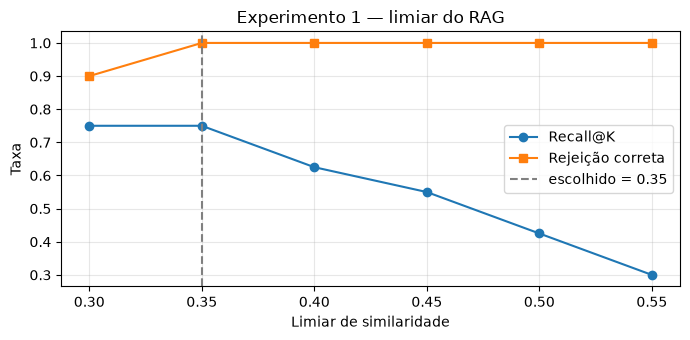

In [8]:
casos_busca = [(frase, doc_id) for doc_id, frases in modelos_chamados.items() for frase in frases]
casos_busca += [(frase, None) for frase in chamados_sem_base]


def avaliar_busca(casos, limiar, top_k=TOP_K):
    recall, rejeicao = [], []
    for texto, doc_esperado in casos:
        ids = [d["id"] for d in buscar_documentos(texto, top_k=top_k, limiar=limiar)]
        if doc_esperado is None:
            rejeicao.append(len(ids) == 0)
        else:
            recall.append(doc_esperado in ids)
    return float(np.mean(recall)), float(np.mean(rejeicao))


linhas = []
for limiar in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55]:
    recall, rejeicao = avaliar_busca(casos_busca, limiar)
    linhas.append({"limiar": limiar, "recall@k": recall, "rejeicao_correta": rejeicao, "media": (recall + rejeicao) / 2})

df_limiar = pd.DataFrame(linhas)
melhor = df_limiar.sort_values(["media", "limiar"], ascending=[False, False]).iloc[0]
LIMIAR_RAG = float(melhor["limiar"])
df_limiar.to_csv(PASTA_SAIDA / "experimento_limiar_rag.csv", index=False)

display(df_limiar.style.format({"recall@k": "{:.1%}", "rejeicao_correta": "{:.1%}", "media": "{:.1%}"}))
print("Limiar escolhido:", LIMIAR_RAG)

plt.figure(figsize=(7, 3.5))
plt.plot(df_limiar["limiar"], df_limiar["recall@k"], marker="o", label="Recall@K")
plt.plot(df_limiar["limiar"], df_limiar["rejeicao_correta"], marker="s", label="Rejeição correta")
plt.axvline(LIMIAR_RAG, color="gray", linestyle="--", label=f"escolhido = {LIMIAR_RAG}")
plt.xlabel("Limiar de similaridade")
plt.ylabel("Taxa")
plt.title("Experimento 1 — limiar do RAG")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(PASTA_SAIDA / "experimento_limiar_rag.png", dpi=120)
plt.show()

## 7. Modelo, prompt e geração

O `SYSTEM_PROMPT` lista os **valores permitidos** de categoria, prioridade e status. As funções:

- `montar_prompt`: regras (system) + CONTEXTO + CHAMADO no formato de chat do modelo;
- `gerar_texto`: geração sem sorteio (`do_sample=False`), sempre a resposta mais provável;
- `extrair_json`: pega do primeiro `{` ao último `}`; se não for JSON válido, devolve `None`;
- `responder`: junta tudo, com um interruptor para ligar/desligar o RAG.

In [9]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"  # necessário para mascarar o prompt corretamente no treino


def carregar_modelo_base():
    modelo = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=DTYPE, low_cpu_mem_usage=True)
    modelo.config.pad_token_id = tokenizer.pad_token_id
    return modelo.to(DEVICE)


def limpar_gpu():
    """Libera a memória da GPU depois de apagar (del) os modelos."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


SYSTEM_PROMPT = """Você é um assistente de atendimento de uma loja virtual.
Use somente as informações presentes no contexto.
Não invente políticas, prazos ou procedimentos.
Se o contexto não for suficiente ou não tratar do chamado, use status "sem_informacao".
Valores permitidos:
- categoria: entrega, defeito, troca, reembolso, cancelamento, pagamento, cupom, fraude, fora_da_base
- prioridade: baixa, media, alta, critica
- status: respondido, sem_informacao
Retorne somente um JSON válido, sem Markdown e sem explicações adicionais,
com as chaves: categoria, prioridade, equipe, procedimento, fonte e status."""


def montar_prompt(chamado, contexto):
    mensagens = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"CONTEXTO:\n{contexto}\n\nCHAMADO:\n{chamado}"},
    ]
    return tokenizer.apply_chat_template(mensagens, tokenize=False, add_generation_prompt=True)


def gerar_texto(modelo, prompt, max_new_tokens=MAX_NEW_TOKENS):
    modelo.eval()
    entradas = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(DEVICE)
    with torch.no_grad():
        saida = modelo.generate(
            **entradas,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    novos = saida[0, entradas["input_ids"].shape[1]:]
    return tokenizer.decode(novos, skip_special_tokens=True).strip()


def extrair_json(texto):
    try:
        objeto = json.loads(texto[texto.index("{"): texto.rindex("}") + 1])
        return objeto if isinstance(objeto, dict) else None
    except (ValueError, json.JSONDecodeError):
        return None


def responder(modelo, chamado, usar_rag=True, top_k=TOP_K):
    inicio = time.perf_counter()
    documentos = buscar_documentos(chamado, top_k=top_k) if usar_rag else []
    texto = gerar_texto(modelo, montar_prompt(chamado, formatar_contexto(documentos)))
    return {
        "texto": texto,
        "json": extrair_json(texto),
        "documentos": [d["id"] for d in documentos],
        "scores": [round(d["score"], 3) for d in documentos],
        "tempo_s": time.perf_counter() - inicio,
    }

tokenizer_config.json: 0.00B [00:00, ?B/s]

d:\generative_ai\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in D:\generative_ai\hf-cache\hub\models--HuggingFaceTB--SmolLM2-360M-Instruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

### Função de avaliação

Aplicada a todos os modelos com os mesmos 12 casos de teste inéditos:

| Métrica | O que mede |
|---|---|
| JSON válido | a resposta é um JSON que o sistema consegue ler |
| Acurácia da categoria | categoria igual à do gabarito |
| F1 macro da prioridade | acerto de prioridade, equilibrando as 4 classes |
| Acurácia da fonte | citou o documento certo (ou nenhum, quando fora da base) |
| Acurácia do status | `respondido` × `sem_informacao` |
| Fonte fundamentada | a fonte citada estava entre os documentos que o RAG trouxe |
| **Pontuação** | média de categoria, prioridade, fonte e status — usada para escolher o melhor experimento |

In [10]:
def avaliar_sistema(modelo, usar_rag=True, casos=None):
    casos = casos if casos is not None else casos_teste
    linhas = []
    for numero, caso in enumerate(casos, start=1):
        saida = responder(modelo, caso["chamado"], usar_rag=usar_rag)
        objeto = saida["json"]
        valido = objeto is not None

        def campo(chave):
            return objeto.get(chave) if valido else "__json_invalido__"

        fonte_prevista = campo("fonte")
        fundamentada = (fonte_prevista in saida["documentos"]) if fonte_prevista else len(saida["documentos"]) == 0

        linhas.append({
            "caso": numero,
            "chamado": caso["chamado"],
            "docs_recuperados": saida["documentos"],
            "json_valido": valido,
            "categoria_real": caso["categoria"],
            "categoria_prevista": campo("categoria"),
            "prioridade_real": caso["prioridade"],
            "prioridade_prevista": campo("prioridade"),
            "fonte_real": caso["doc"],
            "fonte_prevista": fonte_prevista,
            "status_real": caso["status"],
            "status_previsto": campo("status"),
            "fonte_fundamentada": fundamentada,
            "tempo_s": saida["tempo_s"],
            "texto": saida["texto"],
        })

    df = pd.DataFrame(linhas)

    def acuracia(real, previsto):
        return float((df[real].fillna("SEM_FONTE").astype(str) == df[previsto].fillna("SEM_FONTE").astype(str)).mean())

    metricas = {
        "json_valido": float(df["json_valido"].mean()),
        "categoria": acuracia("categoria_real", "categoria_prevista"),
        "prioridade_f1": float(f1_score(
            df["prioridade_real"].astype(str), df["prioridade_prevista"].astype(str),
            labels=PRIORIDADES, average="macro", zero_division=0,
        )),
        "fonte": acuracia("fonte_real", "fonte_prevista"),
        "status": acuracia("status_real", "status_previsto"),
        "fonte_fundamentada": float(df["fonte_fundamentada"].mean()),
        "tempo_medio_s": float(df["tempo_s"].mean()),
    }
    metricas["pontuacao"] = float(np.mean([metricas[k] for k in ["categoria", "prioridade_f1", "fonte", "status"]]))
    return metricas, df


FORMATO_METRICAS = {
    k: "{:.1%}" for k in ["json_valido", "categoria", "prioridade_f1", "fonte", "status", "fonte_fundamentada", "pontuacao"]
}
FORMATO_METRICAS["tempo_medio_s"] = "{:.2f}"

## 8. O "antes": modelo original, sem fine-tuning

Avaliamos o modelo original nas mesmas condições do sistema final (com RAG), para comparar antes × depois.

In [11]:
modelo = carregar_modelo_base()
total_parametros = sum(p.numel() for p in modelo.parameters())
print(f"Parâmetros do modelo: {total_parametros:,} (~{total_parametros / 1e6:.1f} milhões)")

respostas_antes = {}
for caso in casos_demonstracao:
    saida = responder(modelo, caso["chamado"], usar_rag=True)
    respostas_antes[caso["nome"]] = saida["texto"]
    print("=" * 90)
    print(caso["nome"], "| documentos:", saida["documentos"])
    print(saida["texto"])

metricas_base, df_base = avaliar_sistema(modelo, usar_rag=True)
resultados = [{"experimento": "0_modelo_original", "rag": True, **metricas_base}]

del modelo
limpar_gpu()

display(pd.DataFrame(resultados).style.format(FORMATO_METRICAS))

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/724M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Parâmetros do modelo: 361,821,120 (~361.8 milhões)
Entrega atrasada | documentos: ['DOC-001', 'DOC-005']
{
  "categoria": "entrega",
  "prioridade": "baixa",
  "equipe": "meus pedidos",
  "procedimento": "cancelamento",
  "fonte": "Meus Pedidos",
  "status": "respondido"
}
Compra suspeita | documentos: ['DOC-004', 'DOC-006']
{
  "categoria": "prazo_de_reembolso",
  "prioridade": "baixa",
  "equipe": "produto",
  "procedure": "pagamento_recusado",
  "fonte": "Cartão de crédito",
  "status": "respondido"
}
Informação ausente | documentos: []
{
  "categoria": "loja",
  "prioridade": "baixa",
  "equipe": "São Paulo",
  "procedimento": "despesas",
  "fonte": "Banco de Dois",
  "status": "sem_informacao"
}


,experimento,rag,json_valido,categoria,prioridade_f1,fonte,status,fonte_fundamentada,tempo_medio_s,pontuacao
0,0_modelo_original,True,83.3%,16.7%,13.3%,0.0%,25.0%,0.0%,2.27,13.8%


## 9. Conjunto de fine-tuning

O conjunto é sintético. Cada frase é combinada com 3 aberturas ("", "Olá, preciso de ajuda.", "Chamado do usuário:"), e cada abertura usa um **contexto diferente**:

| Abertura | Chamado da base | Chamado fora da base |
|---|---|---|
| 1ª | só o documento certo | contexto vazio |
| 2ª | documento certo + distrator | contexto vazio |
| 3ª | distrator + documento certo | 1 documento **irrelevante** |

Assim o modelo pratica **escolher** o documento certo entre dois e **recusar** quando o documento recuperado não tem relação com o chamado.

**Validação separada por frase:** a última frase de cada documento e as 2 últimas perguntas fora da base vão só para a validação.

In [12]:
aberturas = ["", "Olá, preciso de ajuda. ", "Chamado do usuário: "]
rng = random.Random(SEED)


def resposta_documento(doc):
    return json.dumps({
        "categoria": doc["categoria"],
        "prioridade": doc["prioridade"],
        "equipe": doc["equipe"],
        "procedimento": doc["procedimento"],
        "fonte": doc["id"],
        "status": "respondido",
    }, ensure_ascii=False)


RESPOSTA_SEM_BASE = json.dumps({
    "categoria": "fora_da_base",
    "prioridade": "baixa",
    "equipe": None,
    "procedimento": None,
    "fonte": None,
    "status": "sem_informacao",
}, ensure_ascii=False)


def documento_aleatorio(exceto=None):
    return rng.choice([d for d in base_conhecimento if d["id"] != exceto])


exemplos_treino, exemplos_validacao = [], []

for doc_id, frases in modelos_chamados.items():
    doc = documentos_por_id[doc_id]
    for i, frase in enumerate(frases):
        destino = exemplos_validacao if i == len(frases) - 1 else exemplos_treino
        for j, abertura in enumerate(aberturas):
            if j == 0:
                documentos = [doc]
            else:
                distrator = documento_aleatorio(exceto=doc_id)
                documentos = [doc, distrator] if j == 1 else [distrator, doc]
            destino.append({
                "chamado": abertura + frase,
                "contexto": formatar_contexto(documentos),
                "resposta": resposta_documento(doc),
                "classe": doc_id,
            })

for i, frase in enumerate(chamados_sem_base):
    destino = exemplos_validacao if i >= len(chamados_sem_base) - 2 else exemplos_treino
    for j, abertura in enumerate(aberturas):
        documentos = [documento_aleatorio()] if j == 2 else []
        destino.append({
            "chamado": abertura + frase,
            "contexto": formatar_contexto(documentos),
            "resposta": RESPOSTA_SEM_BASE,
            "classe": "SEM_BASE",
        })

rng.shuffle(exemplos_treino)
rng.shuffle(exemplos_validacao)

print("Treino:", len(exemplos_treino), "| Validação:", len(exemplos_validacao))
display(pd.DataFrame(exemplos_treino)["classe"].value_counts().sort_index().to_frame("treino"))

Treino: 120 | Validação: 30


,treino
classe,
DOC-001,12
DOC-002,12
DOC-003,12
DOC-004,12
DOC-005,12
DOC-006,12
DOC-007,12
DOC-008,12
SEM_BASE,24


## 10. Tokenização

Os tokens do prompt (regras + contexto + chamado) e do preenchimento recebem rótulo `-100`: o modelo **só é cobrado pela resposta JSON**, não por repetir o prompt.

In [13]:
def tokenizar_exemplo(exemplo):
    prompt = montar_prompt(exemplo["chamado"], exemplo["contexto"])
    tokens = tokenizer(
        prompt + exemplo["resposta"] + tokenizer.eos_token,
        add_special_tokens=False,
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length",
    )
    tamanho_prompt = len(tokenizer(prompt, add_special_tokens=False)["input_ids"])
    tokens["labels"] = [
        -100 if (i < tamanho_prompt or mascara == 0) else token
        for i, (token, mascara) in enumerate(zip(tokens["input_ids"], tokens["attention_mask"]))
    ]
    return tokens


# Confere se nenhum exemplo foi cortado (um exemplo cortado perde a resposta).
maior = max(
    len(tokenizer(montar_prompt(ex["chamado"], ex["contexto"]) + ex["resposta"] + tokenizer.eos_token,
                  add_special_tokens=False)["input_ids"])
    for ex in exemplos_treino + exemplos_validacao
)
print(f"Maior exemplo: {maior} tokens (limite MAX_LENGTH = {MAX_LENGTH})")
assert maior <= MAX_LENGTH, "Aumente MAX_LENGTH: há exemplos sendo cortados."

colunas = list(exemplos_treino[0].keys())
treino_tokenizado = Dataset.from_list(exemplos_treino).map(tokenizar_exemplo, remove_columns=colunas)
validacao_tokenizada = Dataset.from_list(exemplos_validacao).map(tokenizar_exemplo, remove_columns=colunas)

print("Treino:", len(treino_tokenizado), "| Validação:", len(validacao_tokenizada))

Maior exemplo: 566 tokens (limite MAX_LENGTH = 640)


Map:   0%|          | 0/120 [00:00<?, ? examples/s]

Map:   0%|          | 0/30 [00:00<?, ? examples/s]

Treino: 120 | Validação: 30


## 11. Experimento 2 — fine-tuning com LoRA e diferentes parâmetros

O LoRA congela os ~362 milhões de pesos originais e treina só matrizes pequenas (rank `r`) nas camadas de atenção e MLP. Cada experimento:

1. recarrega o modelo **original** (para os experimentos não se misturarem);
2. aplica o LoRA com os parâmetros da linha;
3. treina, guardando o melhor checkpoint pela loss de validação;
4. avalia nos 12 casos de teste **com** e **sem** RAG;
5. salva o adaptador em `saidas/adaptadores/<nome>`.

| Exp. | O que varia | Pergunta que responde |
|---|---|---|
| A | configuração da Aula 9 | ponto de partida |
| B | rank menor (r=8) | um adaptador menor perde qualidade? |
| C | mais épocas (5) | treinar mais ajuda ou sobreajusta? |
| D | learning rate menor (5e-5) | passos menores aprendem o suficiente? |

> Tire o print das extensões **GPU Monitor / GPU Environment** enquanto esta célula estiver rodando.

In [14]:
EXPERIMENTOS = [
    {"nome": "A_aula_r16_ep3_lr2e-4", "r": 16, "alpha": 32, "epocas": 3, "lr": 2e-4},
    {"nome": "B_r8_ep3_lr2e-4", "r": 8, "alpha": 16, "epocas": 3, "lr": 2e-4},
    {"nome": "C_r16_ep5_lr2e-4", "r": 16, "alpha": 32, "epocas": 5, "lr": 2e-4},
    {"nome": "D_r16_ep3_lr5e-5", "r": 16, "alpha": 32, "epocas": 3, "lr": 5e-5},
]

MODULOS_LORA = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
historicos = {}


def treinar_experimento(cfg):
    fixar_semente()
    modelo = get_peft_model(carregar_modelo_base(), LoraConfig(
        r=cfg["r"],
        lora_alpha=cfg["alpha"],
        lora_dropout=0.05,
        bias="none",
        task_type=TaskType.CAUSAL_LM,
        target_modules=MODULOS_LORA,
    ))
    modelo.config.use_cache = False
    modelo.enable_input_require_grads()
    modelo.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    treinaveis, total = modelo.get_nb_trainable_parameters()

    argumentos = TrainingArguments(
        output_dir=str(PASTA_SAIDA / "checkpoints" / cfg["nome"]),
        num_train_epochs=cfg["epocas"],
        per_device_train_batch_size=LOTE,
        per_device_eval_batch_size=LOTE,
        gradient_accumulation_steps=ACUMULACAO,
        learning_rate=cfg["lr"],
        warmup_steps=10,
        weight_decay=0.01,
        logging_steps=2,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        save_total_limit=1,
        fp16=USAR_FP16,
        bf16=USAR_BF16,
        report_to="none",
        seed=SEED,
        remove_unused_columns=False,
        optim="adamw_torch",
    )
    trainer = Trainer(
        model=modelo,
        args=argumentos,
        train_dataset=treino_tokenizado,
        eval_dataset=validacao_tokenizada,
        data_collator=default_data_collator,
    )

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    inicio = time.perf_counter()
    trainer.train()
    tempo_treino = time.perf_counter() - inicio
    memoria_gb = torch.cuda.max_memory_allocated() / 1024**3 if torch.cuda.is_available() else 0.0

    historico = pd.DataFrame(trainer.state.log_history)
    historicos[cfg["nome"]] = historico

    modelo.config.use_cache = True
    metricas_rag, df_rag = avaliar_sistema(modelo, usar_rag=True)
    metricas_sem_rag, _ = avaliar_sistema(modelo, usar_rag=False)

    pasta = PASTA_SAIDA / "adaptadores" / cfg["nome"]
    modelo.save_pretrained(pasta)
    tokenizer.save_pretrained(pasta)
    df_rag.to_csv(PASTA_SAIDA / f"avaliacao_{cfg['nome']}.csv", index=False)

    info = {
        "r": cfg["r"], "alpha": cfg["alpha"], "epocas": cfg["epocas"], "lr": cfg["lr"],
        "params_treinaveis": treinaveis, "pct_treinavel": treinaveis / total,
        "loss_treino_final": float(historico["loss"].dropna().iloc[-1]),
        "loss_validacao_melhor": float(historico["eval_loss"].dropna().min()),
        "tempo_treino_s": tempo_treino, "memoria_pico_gb": memoria_gb,
    }
    del trainer, modelo
    limpar_gpu()
    return [
        {"experimento": cfg["nome"], "rag": True, **info, **metricas_rag},
        {"experimento": cfg["nome"], "rag": False, **info, **metricas_sem_rag},
    ]


for cfg in EXPERIMENTOS:
    print("\n" + "#" * 90 + f"\nEXPERIMENTO {cfg['nome']}\n" + "#" * 90)
    resultados.extend(treinar_experimento(cfg))
    pd.DataFrame(resultados).to_csv(PASTA_SAIDA / "resultados_experimentos.csv", index=False)

print("\nTodos os experimentos concluídos.")


##########################################################################################
EXPERIMENTO A_aula_r16_ep3_lr2e-4
##########################################################################################


  0%|          | 0/21 [00:00<?, ?it/s]

{'loss': 1.0277, 'grad_norm': 0.48305943608283997, 'learning_rate': 4e-05, 'epoch': 0.27}
{'loss': 1.0118, 'grad_norm': 0.4901542663574219, 'learning_rate': 8e-05, 'epoch': 0.53}
{'loss': 0.8928, 'grad_norm': 0.41407233476638794, 'learning_rate': 0.00012, 'epoch': 0.8}


  0%|          | 0/8 [00:00<?, ?it/s]

{'eval_loss': 0.9219552278518677, 'eval_runtime': 2.8934, 'eval_samples_per_second': 10.368, 'eval_steps_per_second': 2.765, 'epoch': 0.93}
{'loss': 1.132, 'grad_norm': 0.702985405921936, 'learning_rate': 0.00016, 'epoch': 1.07}
{'loss': 0.8324, 'grad_norm': 0.4171586036682129, 'learning_rate': 0.0002, 'epoch': 1.33}
{'loss': 0.8104, 'grad_norm': 0.34589606523513794, 'learning_rate': 0.00016363636363636366, 'epoch': 1.6}
{'loss': 0.6508, 'grad_norm': 0.3907458782196045, 'learning_rate': 0.00012727272727272728, 'epoch': 1.87}


...

{'eval_loss': 0.9761059880256653, 'eval_runtime': 2.8997, 'eval_samples_per_second': 10.346, 'eval_steps_per_second': 2.759, 'epoch': 0.93}
{'loss': 1.1875, 'grad_norm': 0.7036466002464294, 'learning_rate': 4e-05, 'epoch': 1.07}
{'loss': 0.9367, 'grad_norm': 0.460101455450058, 'learning_rate': 5e-05, 'epoch': 1.33}
{'loss': 1.0257, 'grad_norm': 0.4859977662563324, 'learning_rate': 4.0909090909090915e-05, 'epoch': 1.6}
{'loss': 0.9178, 'grad_norm': 0.451968252658844, 'learning_rate': 3.181818181818182e-05, 'epoch': 1.87}


  0%|          | 0/8 [00:00<?, ?it/s]

{'eval_loss': 0.9175697565078735, 'eval_runtime': 2.8526, 'eval_samples_per_second': 10.517, 'eval_steps_per_second': 2.804, 'epoch': 2.0}
{'loss': 1.2185, 'grad_norm': 0.42827701568603516, 'learning_rate': 2.272727272727273e-05, 'epoch': 2.13}
{'loss': 0.8841, 'grad_norm': 0.41766855120658875, 'learning_rate': 1.3636363636363637e-05, 'epoch': 2.4}
{'loss': 0.9583, 'grad_norm': 0.4696519672870636, 'learning_rate': 4.5454545454545455e-06, 'epoch': 2.67}


  0%|          | 0/8 [00:00<?, ?it/s]

{'eval_loss': 0.891392171382904, 'eval_runtime': 2.8486, 'eval_samples_per_second': 10.532, 'eval_steps_per_second': 2.808, 'epoch': 2.8}
{'train_runtime': 128.8219, 'train_samples_per_second': 2.795, 'train_steps_per_second': 0.163, 'train_loss': 1.001650937965938, 'epoch': 2.8}

Todos os experimentos concluídos.


## 12. Comparação dos experimentos

,experimento,rag,r,epocas,lr,loss_treino_final,loss_validacao_melhor,tempo_treino_s,memoria_pico_gb,json_valido,categoria,prioridade_f1,fonte,status,fonte_fundamentada,pontuacao
0,0_modelo_original,True,—,—,—,—,—,—,—,83.3%,16.7%,13.3%,0.0%,25.0%,0.0%,13.8%
1,A_aula_r16_ep3_lr2e-4,True,16.000000,3.000000,2e-04,0.548,0.494,130,3.09,91.7%,33.3%,4.5%,16.7%,50.0%,16.7%,26.1%
2,A_aula_r16_ep3_lr2e-4,False,16.000000,3.000000,2e-04,0.548,0.494,130,3.09,91.7%,8.3%,13.3%,0.0%,58.3%,0.0%,20.0%
3,B_r8_ep3_lr2e-4,True,8.000000,3.000000,2e-04,0.722,0.658,126,3.02,91.7%,41.7%,34.1%,0.0%,58.3%,0.0%,33.5%
4,B_r8_ep3_lr2e-4,False,8.000000,3.000000,2e-04,0.722,0.658,126,3.02,91.7%,16.7%,36.1%,0.0%,58.3%,0.0%,27.8%
5,C_r16_ep5_lr2e-4,True,16.000000,5.000000,2e-04,0.288,0.293,212,3.09,100.0%,50.0%,17.8%,41.7%,83.3%,41.7%,48.2%
6,C_r16_ep5_lr2e-4,False,16.000000,5.000000,2e-04,0.288,0.293,212,3.09,100.0%,16.7%,14.3%,0.0%,41.7%,0.0%,18.2%
7,D_r16_ep3_lr5e-5,True,16.000000,3.000000,5e-05,0.958,0.891,129,3.09,100.0%,16.7%,16.7%,0.0%,41.7%,0.0%,18.8%
8,D_r16_ep3_lr5e-5,False,16.000000,3.000000,5e-05,0.958,0.891,129,3.09,100.0%,0.0%,16.7%,0.0%,16.7%,0.0%,8.3%


Melhor experimento (pontuação com RAG): C_r16_ep5_lr2e-4


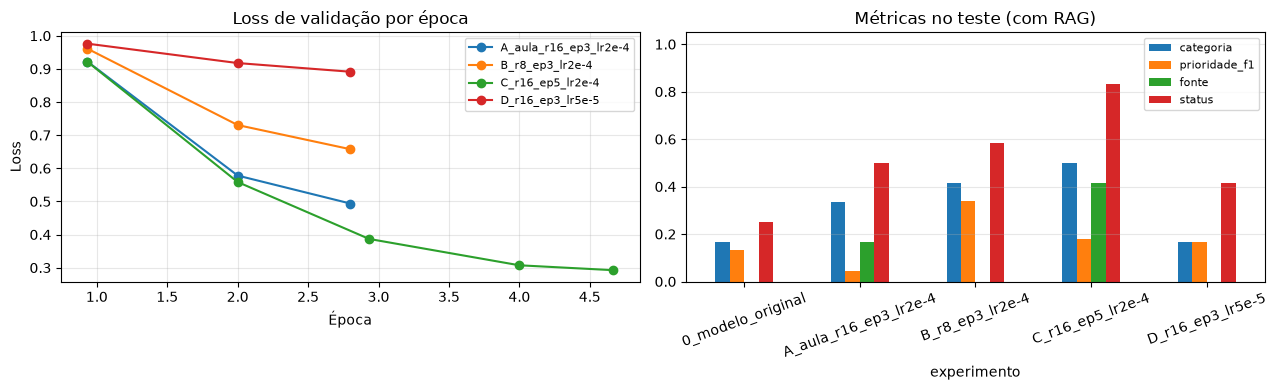

In [15]:
df_resultados = pd.DataFrame(resultados)
colunas_tabela = [
    "experimento", "rag", "r", "epocas", "lr", "loss_treino_final", "loss_validacao_melhor",
    "tempo_treino_s", "memoria_pico_gb", "json_valido", "categoria", "prioridade_f1",
    "fonte", "status", "fonte_fundamentada", "pontuacao",
]
display(
    df_resultados.reindex(columns=colunas_tabela)
    .style.format({**FORMATO_METRICAS, "loss_treino_final": "{:.3f}", "loss_validacao_melhor": "{:.3f}",
                   "tempo_treino_s": "{:.0f}", "memoria_pico_gb": "{:.2f}", "lr": "{:.0e}"}, na_rep="—")
)

com_rag = df_resultados[(df_resultados["rag"]) & (df_resultados["experimento"] != "0_modelo_original")]
MELHOR_EXPERIMENTO = com_rag.sort_values("pontuacao", ascending=False).iloc[0]["experimento"]
print("Melhor experimento (pontuação com RAG):", MELHOR_EXPERIMENTO)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for nome, historico in historicos.items():
    validacao = historico.dropna(subset=["eval_loss"])
    eixos[0].plot(validacao["epoch"], validacao["eval_loss"], marker="o", label=nome)
eixos[0].set_title("Loss de validação por época")
eixos[0].set_xlabel("Época")
eixos[0].set_ylabel("Loss")
eixos[0].grid(alpha=0.3)
eixos[0].legend(fontsize=8)

grafico = df_resultados[df_resultados["rag"]].set_index("experimento")[["categoria", "prioridade_f1", "fonte", "status"]]
grafico.plot(kind="bar", ax=eixos[1], rot=20)
eixos[1].set_title("Métricas no teste (com RAG)")
eixos[1].set_ylim(0, 1.05)
eixos[1].grid(alpha=0.3, axis="y")
eixos[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(PASTA_SAIDA / "comparacao_experimentos.png", dpi=120)
plt.show()

### Curva de aprendizado do melhor experimento

Treino e validação caindo juntos = aprendizado. Treino caindo e validação **subindo** = sobreajuste (decoreba).

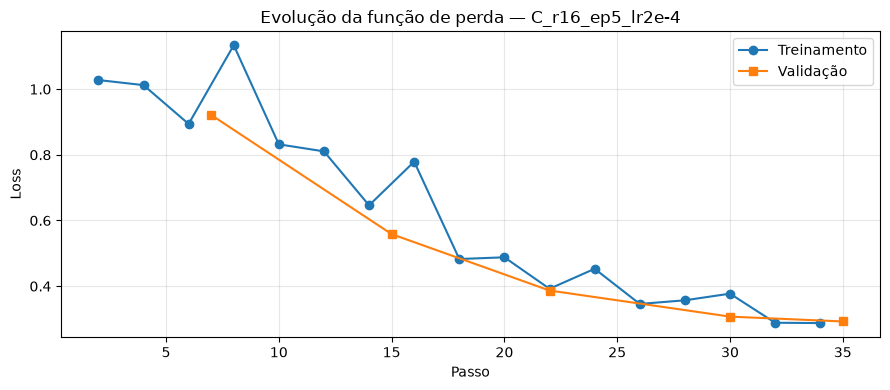

In [16]:
historico = historicos[MELHOR_EXPERIMENTO]
plt.figure(figsize=(9, 4))
dados_treino = historico.dropna(subset=["loss"])
dados_validacao = historico.dropna(subset=["eval_loss"])
plt.plot(dados_treino["step"], dados_treino["loss"], marker="o", label="Treinamento")
plt.plot(dados_validacao["step"], dados_validacao["eval_loss"], marker="s", label="Validação")
plt.xlabel("Passo")
plt.ylabel("Loss")
plt.title(f"Evolução da função de perda — {MELHOR_EXPERIMENTO}")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(PASTA_SAIDA / "curva_melhor_experimento.png", dpi=120)
plt.show()

## 13. Modelo final: antes × depois

Carregamos o modelo original + o adaptador LoRA do melhor experimento e comparamos as respostas dos 3 casos de demonstração.

In [17]:
PASTA_ADAPTADOR = PASTA_SAIDA / "adaptadores" / MELHOR_EXPERIMENTO

modelo_final = PeftModel.from_pretrained(carregar_modelo_base(), str(PASTA_ADAPTADOR)).to(DEVICE)
modelo_final.eval()
modelo_final.config.use_cache = True

for caso in casos_demonstracao:
    depois = responder(modelo_final, caso["chamado"], usar_rag=True)
    print("\n" + "=" * 90)
    print("CASO:", caso["nome"])
    print("CHAMADO:", caso["chamado"])
    print("\nANTES (modelo original + RAG):")
    print(respostas_antes[caso["nome"]])
    print(f"\nDEPOIS ({MELHOR_EXPERIMENTO} + RAG) | documentos: {depois['documentos']} scores: {depois['scores']}")
    print(depois["texto"])


CASO: Entrega atrasada
CHAMADO: Meu pedido deveria ter chegado semana passada e até agora nada.

ANTES (modelo original + RAG):
{
  "categoria": "entrega",
  "prioridade": "baixa",
  "equipe": "meus pedidos",
  "procedimento": "cancelamento",
  "fonte": "Meus Pedidos",
  "status": "respondido"
}

DEPOIS (C_r16_ep5_lr2e-4 + RAG) | documentos: ['DOC-001', 'DOC-005'] scores: [0.403, 0.39]
{"categoria": "entrega", "prioridade": "baixa", "equipe": "financeiro", "procedimento": "Verificar o prazo de entrega em Meus Pedidos e atrasar em 5 dias úteis.", "fonte": "DOC-001", "status": "respondido"}

CASO: Compra suspeita
CHAMADO: Alguém fez uma compra com meu cartão na minha conta sem eu saber.

ANTES (modelo original + RAG):
{
  "categoria": "prazo_de_reembolso",
  "prioridade": "baixa",
  "equipe": "produto",
  "procedure": "pagamento_recusado",
  "fonte": "Cartão de crédito",
  "status": "respondido"
}

DEPOIS (C_r16_ep5_lr2e-4 + RAG) | documentos: ['DOC-004', 'DOC-006'] scores: [0.472, 0.46

### Avaliação detalhada do modelo final

Resposta por resposta nos 12 casos inéditos — útil para discutir os erros no README.

In [18]:
metricas_final, df_final = avaliar_sistema(modelo_final, usar_rag=True)

comparacao = pd.DataFrame([
    {"modelo": "Original + RAG (antes)", **metricas_base},
    {"modelo": f"{MELHOR_EXPERIMENTO} + RAG (depois)", **metricas_final},
]).set_index("modelo")
display(comparacao.style.format(FORMATO_METRICAS))

display(df_final[[
    "caso", "chamado", "docs_recuperados", "categoria_real", "categoria_prevista",
    "prioridade_real", "prioridade_prevista", "fonte_real", "fonte_prevista",
    "status_real", "status_previsto",
]])

,json_valido,categoria,prioridade_f1,fonte,status,fonte_fundamentada,tempo_medio_s,pontuacao
modelo,,,,,,,,
Original + RAG (antes),83.3%,16.7%,13.3%,0.0%,25.0%,0.0%,2.27,13.8%
C_r16_ep5_lr2e-4 + RAG (depois),100.0%,50.0%,17.8%,41.7%,83.3%,41.7%,4.62,48.2%


,caso,chamado,docs_recuperados,categoria_real,categoria_prevista,prioridade_real,prioridade_prevista,fonte_real,fonte_prevista,status_real,status_previsto
0,1,Já passaram dez dias e minha encomenda não apa...,"[DOC-003, DOC-001]",entrega,troca,media,baixa,DOC-001,DOC-001,respondido,respondido
1,2,A tela do notebook veio trincada.,[],defeito,defeito,alta,media,DOC-002,CONTEXTO,respondido,respondido
2,3,"A calça não serviu, quero outra numeração.",[],troca,fora_da_base,baixa,baixa,DOC-003,CONTEXTO: Nenhum documento relevante foi encon...,respondido,sem_informacao
3,4,"Mandei o produto de volta, quando recebo o val...","[DOC-004, DOC-002]",reembolso,reembolso,media,media,DOC-004,DOC-004,respondido,respondido
4,5,"Desisti da compra que fiz hoje cedo, dá para a...","[DOC-005, DOC-003]",cancelamento,cancelamento,media,baixa,DOC-005,DOC-005,respondido,respondido
5,6,A transação foi negada no checkout.,"[DOC-006, DOC-005]",pagamento,pagamento,alta,baixa,DOC-006,DOC-006,respondido,respondido
6,7,O código de desconto da newsletter não é aceito.,[DOC-007],cupom,cupom,baixa,media,DOC-007,DOC-007,respondido,respondido
7,8,Tem um pedido no meu histórico que eu nunca fiz.,[],fraude,fora_da_base,critica,baixa,DOC-008,Nenhum documento relevante foi encontrado na b...,respondido,sem_informacao
8,9,Qual é o salário inicial de um vendedor?,[],fora_da_base,fora_da_base,baixa,baixa,None,Nenhum documento relevante foi encontrado na b...,sem_informacao,sem_informacao
9,10,Vocês têm aplicativo para smart TV?,[],fora_da_base,defeito,baixa,media,None,sem_informacao,sem_informacao,sem_informacao


## 14. Salvando os resultados

A pasta do adaptador guarda só o LoRA (alguns MB), não uma cópia do modelo inteiro. O arquivo `config_final.json` é usado pelo frontend.

In [19]:
config_final = {
    "modelo_base": MODEL_NAME,
    "modelo_embedding": EMBEDDING_NAME,
    "adaptador": str(PASTA_ADAPTADOR),
    "melhor_experimento": MELHOR_EXPERIMENTO,
    "limiar_rag": LIMIAR_RAG,
    "top_k": TOP_K,
    "metricas_teste": metricas_final,
}
with open(PASTA_SAIDA / "config_final.json", "w", encoding="utf-8") as arquivo:
    json.dump(config_final, arquivo, ensure_ascii=False, indent=2)

df_final.to_csv(PASTA_SAIDA / "avaliacao_modelo_final.csv", index=False)
print(json.dumps(config_final, ensure_ascii=False, indent=2))
print("\nArquivos em:", PASTA_SAIDA.resolve())

{
  "modelo_base": "HuggingFaceTB/SmolLM2-360M-Instruct",
  "modelo_embedding": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
  "adaptador": "saidas\\adaptadores\\C_r16_ep5_lr2e-4",
  "melhor_experimento": "C_r16_ep5_lr2e-4",
  "limiar_rag": 0.35,
  "top_k": 2,
  "metricas_teste": {
    "json_valido": 1.0,
    "categoria": 0.5,
    "prioridade_f1": 0.1778846153846154,
    "fonte": 0.4166666666666667,
    "status": 0.8333333333333334,
    "fonte_fundamentada": 0.4166666666666667,
    "tempo_medio_s": 4.6199609583321335,
    "pontuacao": 0.48197115384615385
  }
}

Arquivos em: D:\generative_ai\saidas


## 15. Frontend — atendimento ao cliente (Gradio)

Interface onde o usuário digita o chamado e recebe a resposta do modelo treinado. Mostra o JSON, os documentos recuperados pelo RAG e o tempo de resposta. Dá para desligar o RAG para comparar.

A célula abre o app no navegador (normalmente em <http://127.0.0.1:7860>). Para encerrar, rode `demo.close()`.

In [20]:
import gradio as gr


def atender(chamado, usar_rag, top_k):
    if not chamado or not chamado.strip():
        return {"erro": "Digite um chamado."}, "", "", ""

    saida = responder(modelo_final, chamado.strip(), usar_rag=usar_rag, top_k=int(top_k))

    if saida["documentos"]:
        linhas = [f"- **{doc_id}** — {documentos_por_id[doc_id]['titulo']} (similaridade {score:.3f})"
                  for doc_id, score in zip(saida["documentos"], saida["scores"])]
        docs = "\n".join(linhas)
    elif usar_rag:
        docs = f"_Nenhum documento passou do limiar ({LIMIAR_RAG})._"
    else:
        docs = "_RAG desligado._"

    resposta = saida["json"] if saida["json"] is not None else {"erro": "O modelo não gerou um JSON válido."}
    return resposta, docs, saida["texto"], f"⏱️ {saida['tempo_s']:.2f} s · GPU: {DEVICE}"


exemplos = [
    ["Meu pedido era para chegar ontem e o rastreio não atualiza."],
    ["O fone de ouvido veio sem funcionar o lado esquerdo."],
    ["Quero trocar o vestido por um tamanho maior."],
    ["Apareceu uma compra de R$ 2.000 que eu não fiz."],
    ["O cupom BEMVINDO10 não está funcionando."],
    ["Vocês têm vaga de emprego para estoquista?"],
]

with gr.Blocks(title="Atendimento E-commerce — SmolLM2 + RAG + LoRA") as demo:
    gr.Markdown(
        "# 🛒 Assistente de atendimento — Loja Virtual\n"
        f"SmolLM2-360M ajustado com LoRA (`{MELHOR_EXPERIMENTO}`) + RAG sobre a base de políticas da loja."
    )
    with gr.Row():
        with gr.Column(scale=1):
            entrada = gr.Textbox(label="Chamado do cliente", lines=4, placeholder="Descreva o problema do cliente...")
            with gr.Row():
                usar_rag = gr.Checkbox(value=True, label="Usar RAG (consultar a base)")
                top_k = gr.Slider(1, 3, value=TOP_K, step=1, label="Documentos (top_k)")
            botao = gr.Button("Enviar chamado", variant="primary")
            gr.Examples(examples=exemplos, inputs=entrada, label="Exemplos")
        with gr.Column(scale=1):
            saida_json = gr.JSON(label="Resposta estruturada")
            saida_docs = gr.Markdown(label="Documentos recuperados")
            saida_tempo = gr.Markdown()
            with gr.Accordion("Texto bruto gerado pelo modelo", open=False):
                saida_texto = gr.Textbox(lines=4, show_label=False)

    entradas = [entrada, usar_rag, top_k]
    saidas = [saida_json, saida_docs, saida_texto, saida_tempo]
    botao.click(atender, inputs=entradas, outputs=saidas)
    entrada.submit(atender, inputs=entradas, outputs=saidas)

demo.launch(inbrowser=True)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## 16. Conclusões (preencher após rodar)

- **Limiar do RAG:** _qual valor foi escolhido e como recall × rejeição mudaram._
- **Melhor experimento:** _qual configuração venceu e por quê (ver tabela da seção 12)._
- **Antes × depois:** _o que mudou do modelo original para o ajustado._
- **RAG ligado × desligado:** _comparar as linhas `rag=True` e `rag=False` do mesmo experimento._
- **Erros que ainda acontecem:** _ver a tabela detalhada da seção 13._
- **Limitações:** base pequena (8 documentos), dados sintéticos e avaliação com só 12 casos.